# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [1]:
# Our usual libraries...
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
# import tabulate

In [3]:
! curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

['  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current',
 '                                 Dload  Upload   Total   Spent    Left  Speed',
 '',
 '  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0',
 '100  539k    0  539k    0     0   637k      0 --:--:-- --:--:-- --:--:--  636k',
 '100 9326k    0 9326k    0     0  5009k      0 --:--:--  0:00:01 --:--:-- 5008k',
 '100 22.1M    0 22.1M    0     0  7817k      0 --:--:--  0:00:02 --:--:-- 7816k',
 '100 35.4M    0 35.4M    0     0  9448k      0 --:--:--  0:00:03 --:--:-- 9448k',
 '100 51.5M    0 51.5M    0     0  10.6M      0 --:--:--  0:00:04 --:--:-- 10.6M',
 '100 67.2M    0 67.2M    0     0  11.5M      0 --:--:--  0:00:05 --:--:-- 13.3M',
 '100 82.8M    0 82.8M    0     0  12.1M      0 --:--:--  0:00:06 --:--:-- 14.8M',
 '100 99.2M    0 99.2M    0     0  12.6M      0 --:--:--  0:00:07 --:--:-- 15.6M',
 '100  114M    0  114M    0     0  12.9M      0 --:--:--  0:00:08 --:--:-- 15.7M',

In [5]:
import os

print(os.getcwd())

/Users/zainabfiyyaz/Desktop/python3402/DATA3402.Fall.2026/Labs/Lab.8


In [8]:
!gunzip SUSY.csv.gz

In [20]:
import pandas as pd

filename = "SUSY.csv"

df = pd.read_csv(filename, dtype='float64', names=VarNames)

In [21]:
import pandas as pd

filename = "SUSY.csv"

df = pd.read_csv(filename, dtype='float64', names=VarNames)

In [22]:
print(df.shape)
print(df.head())

(5000000, 19)
   signal    l_1_pT   l_1_eta   l_1_phi    l_2_pT   l_2_eta   l_2_phi  \
0     0.0  0.972861  0.653855  1.176225  1.157156 -1.739873 -0.874309   
1     1.0  1.667973  0.064191 -1.225171  0.506102 -0.338939  1.672543   
2     1.0  0.444840 -0.134298 -0.709972  0.451719 -1.613871 -0.768661   
3     1.0  0.381256 -0.976145  0.693152  0.448959  0.891753 -0.677328   
4     1.0  1.309996 -0.690089 -0.676259  1.589283 -0.693326  0.622907   

        MET   MET_phi   MET_rel  axial_MET       M_R    M_TR_2         R  \
0  0.567765 -0.175000  0.810061  -0.252552  1.921887  0.889637  0.410772   
1  3.475464 -1.219136  0.012955   3.775174  1.045977  0.568051  0.481928   
2  1.219918  0.504026  1.831248  -0.431385  0.526283  0.941514  1.587535   
3  2.033060  1.533041  3.046260  -1.005285  0.569386  1.015211  1.582217   
4  1.087562 -0.381742  0.589204   1.365479  1.179295  0.968218  0.728563   

        MT2       S_R  M_Delta_R  dPhi_r_b  cos_theta_r1  
0  1.145621  1.932632   0.99446

In [24]:
filename="../Lab.7/SUSY.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", 
          "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA). 

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

In [25]:
import sklearn

### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning). 

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

In [26]:
import sklearn.discriminant_analysis as DA
Fisher=DA.LinearDiscriminantAnalysis()

As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing.

In [27]:
N_Train=4000000

Train_Sample=df[:N_Train]
Test_Sample=df[N_Train:]

X_Train=Train_Sample[VarNames[1:]]
y_Train=Train_Sample["signal"]

X_Test=Test_Sample[VarNames[1:]]
y_Test=Test_Sample["signal"]

Test_sig=Test_Sample[Test_Sample.signal==1]
Test_bkg=Test_Sample[Test_Sample.signal==0]


We can train the classifier as follows:

In [28]:
Fisher.fit(X_Train,y_Train)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


We can plot the output, comparing signal and background:

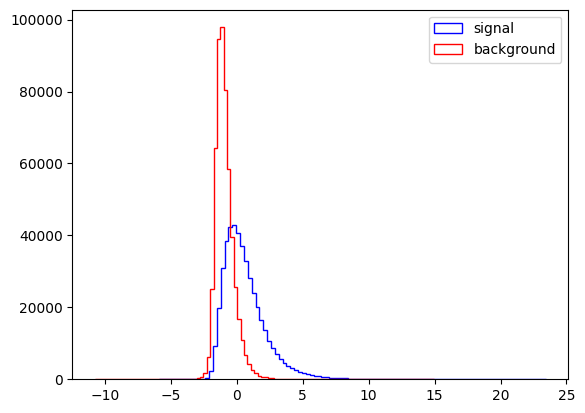

In [29]:
plt.figure()
plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]),bins=100,histtype="step", color="blue", label="signal",stacked=True)
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]),bins=100,histtype="step", color="red", label="background",stacked=True)
plt.legend(loc='upper right')
plt.show()

#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

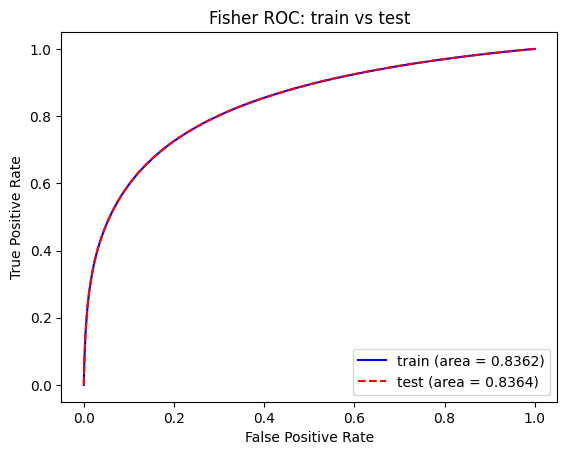

AUC train = 0.8361729591588447
AUC test  = 0.8364009731285001
difference = -0.0002280139696554384


In [30]:
# Exercise 3a: ROC curve on the training sample and the test sample
from sklearn.metrics import roc_curve, auc

# scores from the Fisher discriminant
score_train = Fisher.decision_function(X_Train)
score_test = Fisher.decision_function(X_Test)

fpr_train, tpr_train, thr_train = roc_curve(y_Train, score_train)
fpr_test, tpr_test, thr_test = roc_curve(y_Test, score_test)

auc_train = auc(fpr_train, tpr_train)
auc_test = auc(fpr_test, tpr_test)

plt.figure()
plt.plot(fpr_train, tpr_train, color='blue', label='train (area = %0.4f)' % auc_train)
plt.plot(fpr_test, tpr_test, color='red', linestyle='--', label='test (area = %0.4f)' % auc_test)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Fisher ROC: train vs test')
plt.legend(loc='lower right')
plt.show()

print('AUC train =', auc_train)
print('AUC test  =', auc_test)
print('difference =', auc_train - auc_test)

**Answer (3a):** The train and test ROC curves lie basically on top of each other. The AUC is 0.8362 for train and 0.8364 for test, a difference of only about -0.0002 (the test one is even slightly higher, which is just statistical noise). So there is no real bias. This makes sense because the Fisher discriminant is a very simple model (it only fits one weight per input variable) and we have 4 million training events, so it cannot memorize the training sample.

#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

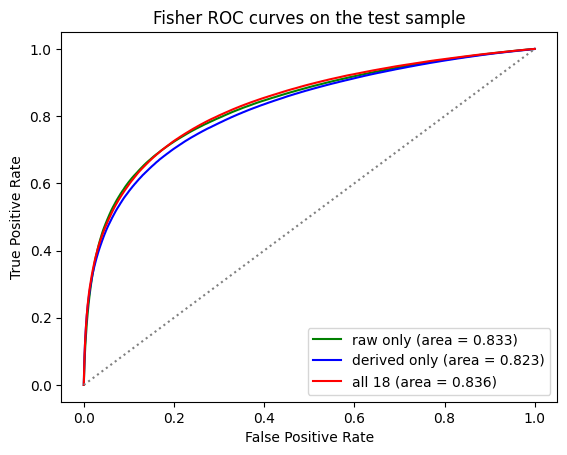

AUC raw only     = 0.8329941371242162
AUC derived only = 0.8231809038576909
AUC all 18       = 0.8364009731285001


In [31]:
# Exercise 3b: three Fisher discriminants with different inputs
# (1) raw only, (2) derived features only, (3) all 18

Fisher_raw = DA.LinearDiscriminantAnalysis()
Fisher_feat = DA.LinearDiscriminantAnalysis()
Fisher_all = DA.LinearDiscriminantAnalysis()

# train each one
Fisher_raw.fit(Train_Sample[RawNames], y_Train)
Fisher_feat.fit(Train_Sample[FeatureNames], y_Train)
Fisher_all.fit(Train_Sample[VarNames[1:]], y_Train)

# ROC curves on the TEST sample
fpr_raw, tpr_raw, _ = roc_curve(y_Test, Fisher_raw.decision_function(Test_Sample[RawNames]))
fpr_feat, tpr_feat, _ = roc_curve(y_Test, Fisher_feat.decision_function(Test_Sample[FeatureNames]))
fpr_all, tpr_all, _ = roc_curve(y_Test, Fisher_all.decision_function(Test_Sample[VarNames[1:]]))

auc_raw = auc(fpr_raw, tpr_raw)
auc_feat = auc(fpr_feat, tpr_feat)
auc_all = auc(fpr_all, tpr_all)

plt.figure()
plt.plot(fpr_raw, tpr_raw, color='green', label='raw only (area = %0.3f)' % auc_raw)
plt.plot(fpr_feat, tpr_feat, color='blue', label='derived only (area = %0.3f)' % auc_feat)
plt.plot(fpr_all, tpr_all, color='red', label='all 18 (area = %0.3f)' % auc_all)
plt.plot([0, 1], [0, 1], color='gray', linestyle=':')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Fisher ROC curves on the test sample')
plt.legend(loc='lower right')
plt.show()

print('AUC raw only     =', auc_raw)
print('AUC derived only =', auc_feat)
print('AUC all 18       =', auc_all)

**Answer (3b):** The AUCs are 0.833 for raw only, 0.823 for derived only, and 0.836 for all 18 inputs. So the raw quantities carry most of the separation: they do better than the derived features alone, and adding the derived features to them only improves the AUC a little (0.833 to 0.836). This makes sense because the derived features are nonlinear functions of the raw quantities, and the raw quantities already contain all of the information. The derived features help a bit because a linear model like the Fisher discriminant cannot build those nonlinear combinations by itself, but the gain is small.

### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

In [32]:
# Exercise 4a: pick 3 classifiers
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier

# 1) Gaussian Naive Bayes
# 2) Quadratic Discriminant Analysis (like Fisher but each class gets its own shape)
# 3) Decision Tree (kept small, depth 6, so it trains fast)
NB = GaussianNB()
QDA = DA.QuadraticDiscriminantAnalysis()
Tree = DecisionTreeClassifier(max_depth=6)

print('chosen: GaussianNB, QDA, DecisionTree(max_depth=6)')

chosen: GaussianNB, QDA, DecisionTree(max_depth=6)


In [33]:
# Exercise 4b: function that does the comparison from 3b for any classifier
from sklearn.base import clone

# some classifiers have decision_function, some only have predict_proba
def get_score(clf, X):
    if hasattr(clf, 'decision_function'):
        return clf.decision_function(X)
    else:
        return clf.predict_proba(X)[:, 1]

def compare_inputs(classifier, name):
    # the three sets of inputs
    input_sets = [RawNames, FeatureNames, VarNames[1:]]
    labels = ['raw only', 'derived only', 'all 18']
    colors = ['green', 'blue', 'red']

    aucs = []
    all_model = None

    plt.figure()
    for i in range(3):
        cols = input_sets[i]

        # make a fresh copy so each fit starts from scratch
        clf = clone(classifier)
        clf.fit(Train_Sample[cols], y_Train)

        score = get_score(clf, Test_Sample[cols])
        fpr, tpr, thr = roc_curve(y_Test, score)
        a = auc(fpr, tpr)
        aucs.append(a)

        plt.plot(fpr, tpr, color=colors[i], label=labels[i] + ' (area = %0.3f)' % a)

        if i == 2:
            all_model = clf   # keep the one trained on all 18 inputs

    plt.plot([0, 1], [0, 1], color='gray', linestyle=':')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(name + ': ROC curves on the test sample')
    plt.legend(loc='lower right')
    plt.show()

    print(name, 'AUCs -> raw: %0.3f, derived: %0.3f, all: %0.3f' % (aucs[0], aucs[1], aucs[2]))
    return aucs, all_model

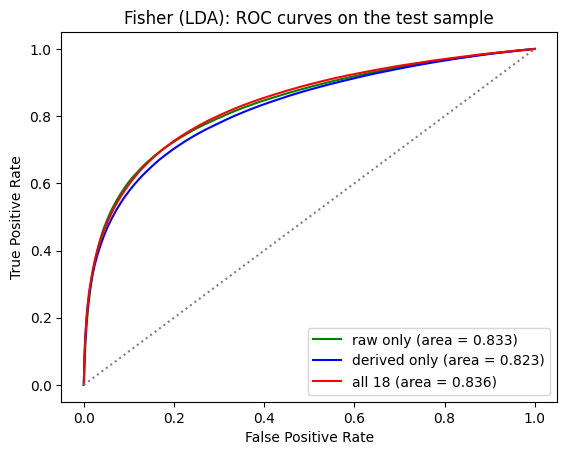

Fisher (LDA) AUCs -> raw: 0.833, derived: 0.823, all: 0.836


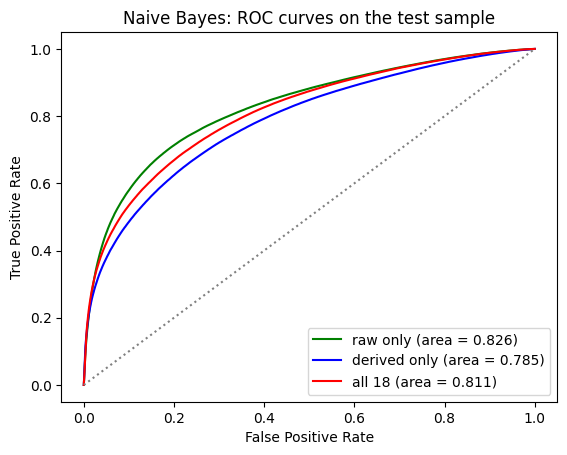

Naive Bayes AUCs -> raw: 0.826, derived: 0.785, all: 0.811


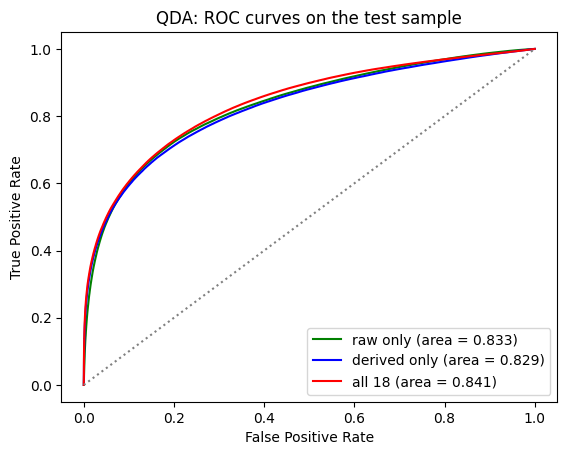

QDA AUCs -> raw: 0.833, derived: 0.829, all: 0.841


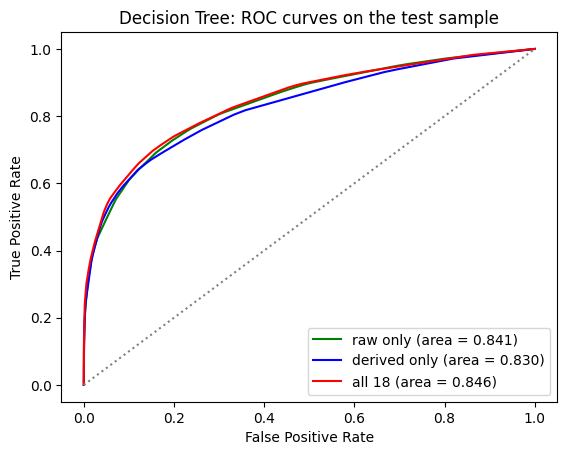

Decision Tree AUCs -> raw: 0.841, derived: 0.830, all: 0.846


In [34]:
# run it on each classifier 
results = {}   # name -> [aucs, model trained on all 18]

classifiers = [('Fisher (LDA)', DA.LinearDiscriminantAnalysis()),
               ('Naive Bayes', NB),
               ('QDA', QDA),
               ('Decision Tree', Tree)]

for name, clf in classifiers:
    aucs, model = compare_inputs(clf, name)
    results[name] = [aucs, model]

In [36]:
# which method is best? 
best_name = ''
best_auc = 0
for name in results:
    a = results[name][0][2]
    print(name, a)
    if a > best_auc:
        best_auc = a
        best_name = name

print('best method:', best_name, 'with AUC =', best_auc)
best_model = results[best_name][1]

Fisher (LDA) 0.8364009731285001
Naive Bayes 0.8112058328666776
QDA 0.8413632247205639
Decision Tree 0.8461845386052902
best method: Decision Tree with AUC = 0.8461845386052902


In [40]:
# Exercise 4c: maximal significance sigma_S = N_S / sqrt(N_S + N_B)
# Each one is (name, total signal events, total background events) BEFORE any cut.
scenarios = [('Scenario 1', 100, 1000),
             ('Scenario 2', 100, 10000),
             ('Scenario 3', 1000, 1000),
             ('Scenario 4', 1000, 10000)]

# scores of the best classifier on the test sample (all 18 inputs)
score_best = get_score(best_model, X_Test)
fpr_b, tpr_b, thr_b = roc_curve(y_Test, score_best)

best_cuts = {}      # scenario name -> best cut on the classifier output
best_sigs = {}      # scenario name -> max significance
best_index = {}     # scenario name -> position in the roc arrays

for name, S_tot, B_tot in scenarios:
    max_sig = 0
    max_i = 0
    # try every cut and keep the one with the biggest significance
    for i in range(len(thr_b)):
        N_S = tpr_b[i] * S_tot     # signal events left after the cut
        N_B = fpr_b[i] * B_tot     # background events left after the cut
        if N_S + N_B > 0:
            sig = N_S / np.sqrt(N_S + N_B)
            if sig > max_sig:
                max_sig = sig
                max_i = i
    best_cuts[name] = thr_b[max_i]
    best_sigs[name] = max_sig
    best_index[name] = max_i
    print(name, ': max significance = %0.3f at cut = %0.4f' % (max_sig, thr_b[max_i]))

Scenario 1 : max significance = 5.255 at cut = 0.7713
Scenario 2 : max significance = 3.562 at cut = 0.9684
Scenario 3 : max significance = 24.286 at cut = 0.3428
Scenario 4 : max significance = 16.619 at cut = 0.7713


### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

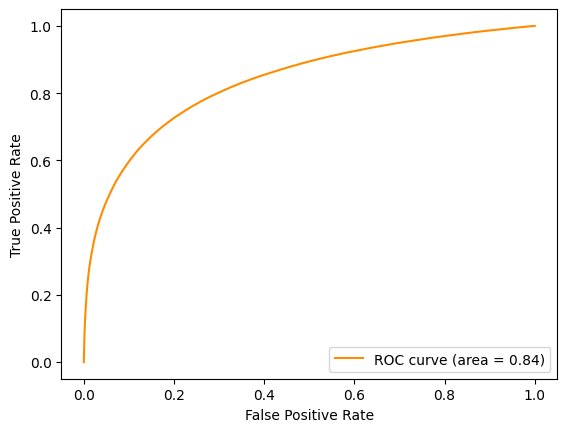

In [41]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()


#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance. 


In [42]:
# Exercise 5b: table of metrics for the best method in each scenario
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

table = pd.DataFrame(columns=['Scenario', 'Cut', 'TPR', 'FPR', 'AUC', 'Precision', 'Recall', 'F1', 'Accuracy', 'Max significance'])

roc_auc_best = auc(fpr_b, tpr_b)   # same for all scenarios (it does not depend on the cut)

row = 0
for name, S_tot, B_tot in scenarios:
    cut = best_cuts[name]

    # classify the test events using the cut for this scenario
    y_pred = (score_best >= cut) * 1

    # TPR and FPR from the confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_Test, y_pred).ravel()
    tpr_val = tp / (tp + fn)
    fpr_val = fp / (fp + tn)

    table.loc[row] = [name,
                      cut,
                      tpr_val,
                      fpr_val,
                      roc_auc_best,
                      precision_score(y_Test, y_pred),
                      recall_score(y_Test, y_pred),
                      f1_score(y_Test, y_pred),
                      accuracy_score(y_Test, y_pred),
                      best_sigs[name]]
    row = row + 1

print('Method used:', best_name)
display(table.round(4))

Method used: Decision Tree


,Scenario,Cut,TPR,FPR,AUC,Precision,Recall,F1,Accuracy,Max significance
0,Scenario 1,0.7713,0.5199,0.0459,0.8462,0.9055,0.5199,0.6605,0.7551,5.2553
1,Scenario 2,0.9684,0.2407,0.0022,0.8462,0.9895,0.2407,0.3872,0.6509,3.5622
2,Scenario 3,0.3428,0.8215,0.3227,0.8462,0.6828,0.8215,0.7458,0.7434,24.2861
3,Scenario 4,0.7713,0.5199,0.0459,0.8462,0.9055,0.5199,0.6605,0.7551,16.6186
